# AttentionDCA walkthrough: from sequences to a contact map

This notebook runs the whole pipeline of the package on the response regulator family:

1. **The alignment**: read the sequences and compute their weights.
2. **The model**: load the trained model from `results/`, or train one if there is none.
3. **Sanity checks**: the save and load round trip, the structure of the attention, and the held-out pseudo-likelihood.
4. **The ground truth**: map the crystal structure of CheY onto the alignment columns.
5. **Contact prediction**: two contact scores and their precision.
6. **The final contact map.**

Run it from the repository root. With the trained model in `results/` it takes about a minute.
Without one, training takes 15 to 30 minutes on 4 CPU cores and less on a GPU.

In [1]:
import os
import tempfile

import matplotlib.pyplot as plt
import numpy as np
import torch

from attention_dca import (MSA, AMINO_ACIDS, AttentionDCA, align_to_profile, attention_score, distance_map,
                           frobenius_score, plot_contact_maps, plot_ppv, plot_training, ppv_curve, rank_contacts,
                           read_chain, secondary_structure)

plt.style.use("options.mplstyle")
torch.set_num_threads(4)

FASTA      = "data/RR_50000.fasta.gz"      # 50,000 response regulator receiver domains (Pfam PF00072)
PDB, CHAIN = "data/3chy.pdb", "A"          # E. coli CheY, the ground truth
H, d, SEED = 128, 17, 0                    # heads, inner dimension of Q and K, initialisation seed
RUN_DIR    = f"results/RR_50000_H{H}_d{d}_s{SEED}"

## 1. The alignment

`MSA` reads the FASTA file into integer tokens $Z \in \{0, \dots, 20\}^{M \times L}$, with 20 for the gap.
It drops sequences that are more than 90% gaps, and duplicate sequences.

Related sequences are heavily oversampled in sequence databases. Each sequence therefore gets the weight
$w_m = 1 / |\{n : d_H(x^m, x^n) < \theta L\}|$, the inverse number of its neighbours in Hamming distance.
A clade of near-identical sequences then counts about once, and $M_\mathrm{eff} = \sum_m w_m$ is the effective
number of independent sequences. The weights take $O(M^2 L)$ time, so they are cached next to the FASTA file.

In [2]:
msa = MSA(FASTA)
L, q = msa.L, 21

alphabet = AMINO_ACIDS + "-"
print("\nFirst five sequences:")
for z in msa.Z[:5]:
    print("  " + "".join(alphabet[t] for t in z))

MSA loaded    : M=50000 (50000 before filtering), L=111, theta=0.447, Meff=12816

First five sequences:
  ILVVEDDTTLFAEIESRFAQWSYEVYGINDFNKVMEEFTVLKPELVIIDIQLPKFDGFHWCRMIRTHS-NVPIIFLSSRDHPTDMVMSMQLGADDYIQKPFHFEVLIAKVQ
  -LLVEDDESLALGIEFSLKDGGYEVFRTSTVEGGRDLFHREPFDLILLDVNLPDGNGYELCKYIRESS-EVPIIFLTALDDEVNIVQGLEIGGDDYITKPFRVRELLSRIK
  ILVVDDEPEVRAAVEDGLAVEGYEVRGAADGLAALSEVASWQPDALVLDVMMPVLDGLAVCRRLRALDDRTPILVLTALDSVSERVDGLDAGADDYLVKPFALDELVARVR
  ILVCDDEKDIVSALEIYLTADGYQVFTAYNGREAVDILNKEEIHLVLMDIMMPEMNGISAMVKIREKS-NVPVILLTAKSEDTDKILGLTVGADDYVTKPFNPVELQARVK
  ILVVDDEPQIRRFLHICLGSQGYEMSEADTAATGLQAAALTQPDLVVMDLGLPDMDGQLMLQQLREFF-QGPVIVLSVRNGEKDKVQALDSGANDYVEKPFGANELLARIR


On the left, the number of close relatives spans three orders of magnitude, from unique sequences to clades of over a thousand,
which is what the weights even out. On the right is the conservation profile. The
entropy $S_i = -\sum_a f_i(a) \log f_i(a)$ of the weighted frequencies $f_i(a)$ is low at conserved columns, and those are often
functional sites.

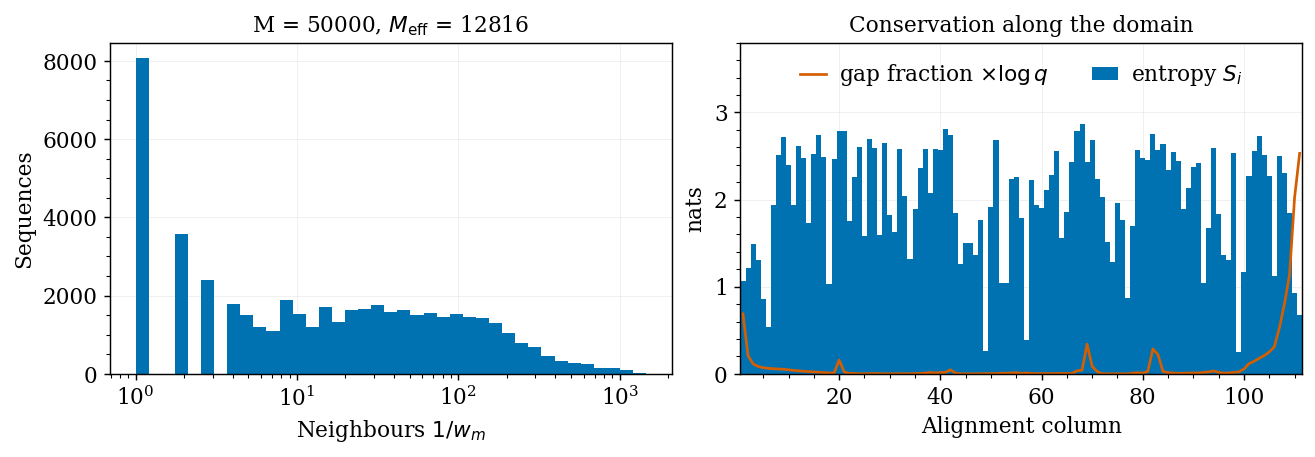

In [3]:
f = msa.profile()                                                   # (L, q), weighted frequencies
S = -(f * np.log(np.where(f > 0, f, 1.0))).sum(axis=1)              # (L,), column entropy

fig, (ax_w, ax_S) = plt.subplots(1, 2, figsize=(10, 3.4))
ax_w.hist(1.0 / msa.w, bins=np.logspace(0, np.log10((1.0 / msa.w).max()), 40))
ax_w.set(xscale="log", xlabel=r"Neighbours $1 / w_m$", ylabel="Sequences",
         title=f"M = {msa.M}, $M_\\mathrm{{eff}}$ = {msa.Meff:.0f}")
ax_S.bar(np.arange(1, L + 1), S, width=1.0, label="entropy $S_i$")
ax_S.plot(np.arange(1, L + 1), f[:, -1] * np.log(q), color="C3", lw=1.5, label=r"gap fraction $\times \log q$")
ax_S.set(xlabel="Alignment column", ylabel="nats", xlim=(0.5, L + 0.5), ylim=(0, 3.8), title="Conservation along the domain")
ax_S.legend(loc="upper center", ncols=2);

## 2. The model: load or train

Each head $h$ of a single attention layer defines which sites interact, $A^h$, and how amino acids interact, $V^h$:

$$A^h_{ij} = \mathrm{softmax}_j\Big(\sum_d Q^h_{di} K^h_{dj}\Big), \qquad J_{ij}(a,b) = \sum_{h=1}^{H} A^h_{ij}\, V^h(a,b) \quad (i \neq j).$$

The $J_{ij}(a, b)$ are the couplings of a Potts model. The model is trained by minimising the weighted, $L_2$-regularised negative
pseudo-likelihood of the conditionals $P(x_i = a \mid x_{\setminus i}) \propto \exp \sum_{j \neq i} J_{ij}(a, x_j)$.
`fit` holds out 20% of the sequences for early stopping and restores the best parameters.

If `RUN_DIR` contains a saved model, it is loaded. Otherwise a model is trained and saved there.

In [4]:
if os.path.exists(os.path.join(RUN_DIR, "params.npz")):
    print(f"Loading the trained model from {RUN_DIR}")
    model = AttentionDCA.load(RUN_DIR)
else:
    print("No trained model found: training one, about 15 to 30 minutes on 4 CPU cores")
    model = AttentionDCA(L=L, H=H, d=d, seed=SEED)
    model.fit(msa)
    model.save(RUN_DIR)

n_params = sum(p.numel() for p in model.parameters())
n_potts  = L * (L - 1) // 2 * q**2
print(f"{n_params:,} parameters on {model.device}, against {n_potts:,} couplings of a full Potts model "
      f"({n_potts / n_params:.0f}x more)")

Loading the trained model from results/RR_50000_H128_d17_s0
539,520 parameters on cpu, against 2,692,305 couplings of a full Potts model (5x more)


The training history is saved with the model. The validation objective levels off, and early stopping restores the epoch
with the lowest validation objective:

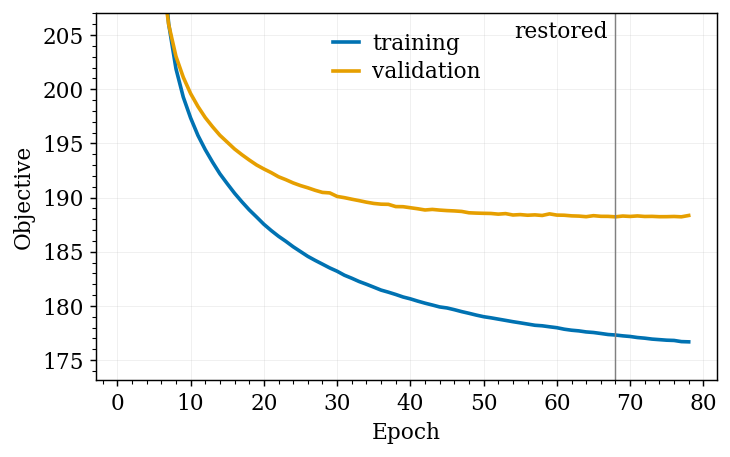

In [5]:
fig, ax = plot_training(model.history, model.fit_config["best_epoch"])

## 3. Sanity checks

**Saving and loading.** A model written with `save` and read back with `load` must give exactly the same couplings.

In [6]:
with tempfile.TemporaryDirectory() as tmp:
    model.save(tmp)
    reloaded = AttentionDCA.load(tmp)

with torch.no_grad():
    assert torch.equal(model.couplings(), reloaded.couplings())
assert reloaded.fit_config == model.fit_config and len(reloaded.history) == len(model.history)
print("save -> load reproduces the parameters, the training configuration and the history")

save -> load reproduces the parameters, the training configuration and the history


**The structure of the attention.** The softmax runs over all $j$ and the diagonal is removed afterwards. Each $A^h$ is therefore
non-negative, its diagonal is zero, and its rows sum to at most 1. A site never couples to itself, so $J_{ii} = 0$.

In [7]:
with torch.no_grad():
    A = model.attention()                                           # (H, L, L)
    J = model.couplings()                                           # (L, q, L, q)

row_sums = A.sum(dim=2)
assert (A >= 0).all() and (A.diagonal(dim1=1, dim2=2) == 0).all() and (row_sums <= 1 + 1e-6).all()
assert (J[torch.arange(L), :, torch.arange(L), :] == 0).all()
print(f"A: {tuple(A.shape)}, row sums between {row_sums.min():.3f} and {row_sums.max():.3f}")
print(f"J: {tuple(J.shape)}, zero on the diagonal blocks")

A: (128, 111, 111), row sums between 0.009 and 1.000
J: (111, 21, 111, 21), zero on the diagonal blocks


**Generalisation.** The model should predict residues of sequences it never saw. The cell below rebuilds the validation split that
`fit` held out, since that split is fixed by the seed. It then measures the per-site perplexity
$\exp\big(-\frac{1}{L}\langle \sum_i \log P(x_i \mid x_{\setminus i}) \rangle_w\big)$, the effective number of amino acids the model
hesitates between at each position. The baseline is an independent-site model $P(x_i) = f_i(x_i)$. Its profile is computed on
all sequences, validation included, which favours the baseline. Guessing uniformly gives $q = 21$, and the randomly initialised
model is even worse than that.

In [8]:
order   = torch.randperm(msa.M, generator=torch.Generator().manual_seed(SEED))
val_idx = order[:int(model.fit_config["val_frac"] * msa.M)].numpy()
Z_val, w_val = msa.Z[val_idx], msa.w[val_idx] / msa.w[val_idx].sum()


def perplexity(m: AttentionDCA) -> float:
    with torch.no_grad():
        log_P = m.log_conditionals(torch.from_numpy(Z_val).long().to(m.device), m.couplings()).cpu().numpy()
    return float(np.exp(-(w_val @ log_P) / L))


log_P_profile = np.log(f[np.arange(L), Z_val] + 1e-10).sum(axis=1)  # independent sites
results = {"uniform guess": float(q),
           "untrained model": perplexity(AttentionDCA(L=L, H=H, d=d, seed=SEED)),
           "independent sites": float(np.exp(-(w_val @ log_P_profile) / L)),
           "trained AttentionDCA": perplexity(model)}

print(f"Per-site perplexity on {len(val_idx)} held-out sequences:")
for name, value in results.items():
    print(f"  {name:22s} {value:5.2f}")

Per-site perplexity on 10000 held-out sequences:
  uniform guess          21.00
  untrained model        34.74
  independent sites       7.37
  trained AttentionDCA    5.04


## 4. The ground truth: CheY on the alignment

A PDB chain does not share the numbering of the alignment. `align_to_profile` aligns the CheY sequence to the family profile
$f_i(a)$ and returns which residue sits in which column.

As a check, the catalytic residues of CheY should land on columns where that amino acid is also the most common one in the family. These are the
phosphorylated D57, the acidic pocket D12 and D13 that binds Mg²⁺, and T87 and K109, which relay the activation.

In [9]:
seq, res_ids, _, _ = read_chain(PDB, CHAIN)
col_to_res = align_to_profile(seq, f)                               # residue index per column, -1 if none
print(f"CheY: {len(seq)} resolved residues, {np.sum(col_to_res >= 0)}/{L} columns mapped\n")

for res_id in [12, 13, 57, 87, 109]:
    r   = np.flatnonzero(res_ids == res_id)[0]
    col = np.flatnonzero(col_to_res == r)[0]
    a   = seq[r]
    print(f"  {a}{res_id:<4d} -> column {col + 1:3d}, where {f[col, AMINO_ACIDS.index(a)]:4.0%} of the family has {a}")

CheY: 128 resolved residues, 111/111 columns mapped

  D12   -> column   5, where  59% of the family has D
  D13   -> column   6, where  90% of the family has D
  D57   -> column  49, where  96% of the family has D
  T87   -> column  77, where  63% of the family has T
  K109  -> column  99, where  96% of the family has K


`distance_map` reads the minimum heavy-atom distance $D_{ij}$ between every pair of mapped columns. Two columns are in contact when
$D_{ij} < 8$ Å. Pairs closer than 6 positions along the sequence are excluded from the evaluation, because they are trivially close.

In [10]:
D  = distance_map(PDB, msa, CHAIN)                                  # (L, L), NaN for unmapped columns
ss = secondary_structure(PDB, msa, CHAIN)                           # helices and strands, for the figures

i, j  = np.triu_indices(L, k=6)
known = ~np.isnan(D[i, j])
n_contacts = int((D[i, j][known] < 8).sum())
print(f"{n_contacts} contacts among {known.sum()} pairs with |i - j| >= 6: "
      f"a random pair is a contact {n_contacts / known.sum():.0%} of the time")
print("Secondary structure:", " ".join(label for label, _, _ in ss))

Structure     : data/3chy.pdb chain A, 111/111 columns mapped
731 contacts among 5565 pairs with |i - j| >= 6: a random pair is a contact 13% of the time
Secondary structure: β1 α1 β2 α2 β3 α3 β4 α4 β5 α5


## 5. Contact prediction

Two contact scores are compared:

* **Couplings**, the classical DCA score. The couplings are symmetrised, moved to the zero-sum gauge, and reduced to the
  Frobenius norm $\lVert J_{ij} \rVert$ over the 20 amino acids.
* **Attention**, the symmetrised attention matrices averaged over the heads, $\frac{1}{H}\sum_h A^h_{ij}$. It ignores $V$
  entirely.

Both are corrected with the average product correction $S_{ij} - S_{i\cdot} S_{\cdot j} / S_{\cdot\cdot}$. This removes the part of a
score that only reflects how strong a site is overall. The pairs are ranked by score. PPV@n is the fraction of the $n$ best pairs that
are real contacts.

In [12]:
scores = {"couplings": frobenius_score(model), "attention": attention_score(model)}

cutoffs = {"L/2": L // 2, "L": L, "2L": 2 * L, "3L": 3 * L}
print(f"{'':11s}" + "".join(f"{'PPV@' + k:>9s}" for k in cutoffs))
for name, S_ij in scores.items():
    ppv = ppv_curve(rank_contacts(S_ij), D)
    print(f"{name:11s}" + "".join(f"{ppv[n - 1]:9.2f}" for n in cutoffs.values()))

             PPV@L/2    PPV@L   PPV@2L   PPV@3L
couplings       0.93     0.91     0.81     0.69
attention       0.95     0.89     0.80     0.71


The precision stays high well past $n = L$. The gray line is a perfect predictor, which is limited only by how many contacts
CheY has.

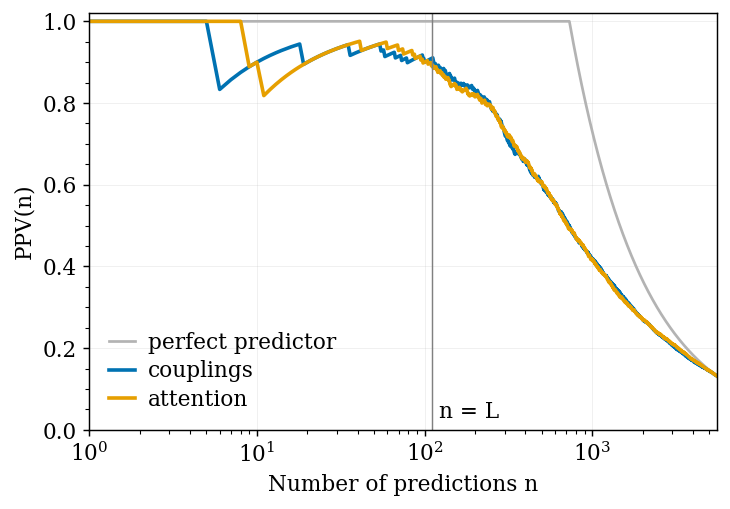

In [13]:
fig, ax = plot_ppv(scores, D)

The ten strongest predictions in CheY numbering. The model only saw sequences, yet nearly all of them touch in the crystal structure,
and salt bridges such as R18–E35 rank first:

In [14]:
for i, j in rank_contacts(scores["couplings"])[:10]:
    r_i, r_j = col_to_res[i], col_to_res[j]
    print(f"  {seq[r_i]}{res_ids[r_i]:<4d} - {seq[r_j]}{res_ids[r_j]:<4d} {D[i, j]:4.1f} Å" + ("" if D[i, j] < 8 else "   (no contact)"))

  R18   - E35    2.7 Å
  R22   - E35    3.0 Å
  E34   - Y51    3.6 Å
  R18   - E37    4.1 Å
  G39   - M63    3.0 Å
  N59   - E89    8.6 Å   (no contact)
  A36   - K45    4.3 Å
  V40   - N62    4.5 Å
  V11   - A42    3.8 Å
  L24   - A113   3.7 Å


## 6. The final contact map

The $2L = 222$ strongest pairs of each score are shown in the upper triangle. The true contacts of CheY are in gray, and the lower triangle
shows the structure alone for comparison. The strip on top marks the β-strands and α-helices of the flavodoxin-like
$(\beta\alpha)_5$ fold. The β-sheet shows up as lines across the map: parallel strands give lines parallel to the diagonal, and
helices packing onto strands give the off-diagonal blocks.

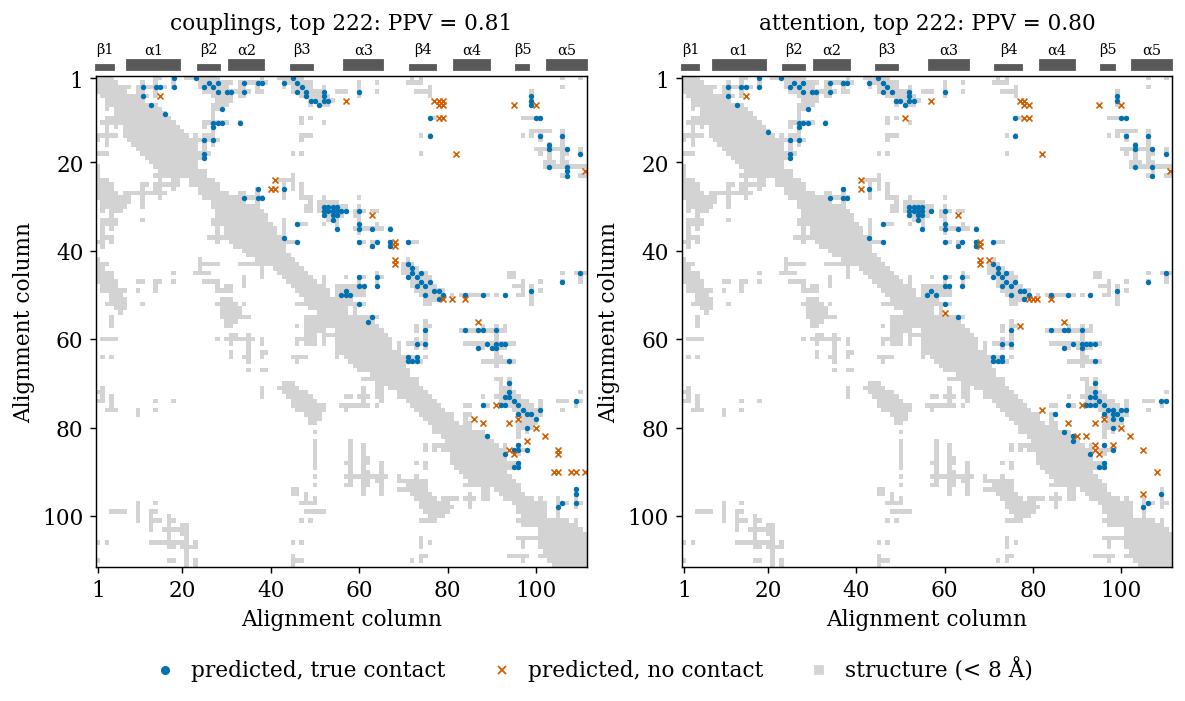

In [15]:
fig, axes = plot_contact_maps(scores, D, n_pred=2 * L, ss=ss)

Most red crosses are near misses, less than 12 Å apart. `run.py` goes further. Many of the remaining far-off predictions turn out to
be contacts across the PhoB homodimer (PDB 1ZES). Single heads can also be read: some have learned salt bridges without being told about
charge. See the README for these results.